# Industrial Supply Chain & Late-Delivery Risk Predictor (Manufacturing Case Study)

## 1. Problem Framing & Business Objective
* *Who has the problem?* Manufacturing and industrial production facilities (such as fertilizer production plants) managing multi-line production and tight B2B order schedules.
* *What decision does the model support?* Determining at order intake/dispatch whether a shipment is at high risk of late delivery, enabling operations managers to prioritize production lines, adjust dispatch schedules, or proactively notify clients.
* *Target Variable:* is_late (Binary Classification: 1 = Late Delivery Risk, 0 = On-Time Delivery).
* *Key Business Metric:* *Recall* and *F1-Score* for the positive class (Late). Missing a delayed shipment (False Negative) leads to contract penalties, lost B2B client trust, and operational bottlenecks—making Recall more critical than raw accuracy.
*

In [25]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

# Download real Supply Chain dataset directly from Kaggle
path = kagglehub.dataset_download("shashwatwork/dataco-smart-supply-chain-for-big-data-analysis")
csv_file = os.path.join(path, "DataCoSupplyChainDataset.csv")

# Load first 15,000 rows for fast processing
raw_df = pd.read_csv(csv_file, encoding='ISO-8859-1', nrows=15000)
print("Dataset loaded successfully from Kaggle!")

# Select operational features relevant to manufacturing & dispatch logistics
cols_to_keep = [
    'Type',
    'Days for shipping (real)',
    'Days for shipment (scheduled)',
    'Delivery Status',
    'Late_delivery_risk',
    'Category Name',
    'Customer Segment',
    'Order Item Quantity',
    'Sales',
    'Order Region',
    'Shipping Mode'
]

df = raw_df[cols_to_keep].copy()

print("Dataset Dimensions:", df.shape)
display(df.head())

Using Colab cache for faster access to the 'dataco-smart-supply-chain-for-big-data-analysis' dataset.
Dataset loaded successfully from Kaggle!
Dataset Dimensions: (15000, 11)


,Type,Days for shipping (real),Days for shipment (scheduled),Delivery Status,Late_delivery_risk,Category Name,Customer Segment,Order Item Quantity,Sales,Order Region,Shipping Mode
0,DEBIT,3,4,Advance shipping,0,Sporting Goods,Consumer,1,327.75,Southeast Asia,Standard Class
1,TRANSFER,5,4,Late delivery,1,Sporting Goods,Consumer,1,327.75,South Asia,Standard Class
2,CASH,4,4,Shipping on time,0,Sporting Goods,Consumer,1,327.75,South Asia,Standard Class
3,DEBIT,3,4,Advance shipping,0,Sporting Goods,Home Office,1,327.75,Oceania,Standard Class
4,PAYMENT,2,4,Advance shipping,0,Sporting Goods,Corporate,1,327.75,Oceania,Standard Class


## 2. Data Understanding & Quality Check
Inspecting data types, missing values, summary statistics, and target class balance (Late_delivery_risk).

In [26]:
# Check data types and non-null counts
print("--- Dataset Info & Data Types ---")
df.info()

# Check for missing values
print("\n--- Missing Values Count ---")
print(df.isnull().sum())

# Summary statistics for numerical columns
print("\n--- Numerical Summary Statistics ---")
display(df.describe())

# Check target class balance (0 = On-Time, 1 = Late Risk)
print("\n--- Target Class Distribution (%) ---")
print(df['Late_delivery_risk'].value_counts(normalize=True).round(4) * 100)

--- Dataset Info & Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Type                           15000 non-null  object 
 1   Days for shipping (real)       15000 non-null  int64  
 2   Days for shipment (scheduled)  15000 non-null  int64  
 3   Delivery Status                15000 non-null  object 
 4   Late_delivery_risk             15000 non-null  int64  
 5   Category Name                  15000 non-null  object 
 6   Customer Segment               15000 non-null  object 
 7   Order Item Quantity            15000 non-null  int64  
 8   Sales                          15000 non-null  float64
 9   Order Region                   15000 non-null  object 
 10  Shipping Mode                  15000 non-null  object 
dtypes: float64(1), int64(4), object(6)
memory usage: 1.3+ MB

--- Missing Va

,Days for shipping (real),Days for shipment (scheduled),Late_delivery_risk,Order Item Quantity,Sales
count,15000.000000,15000.000000,15000.0000,15000.000000,15000.000000
mean,3.723733,3.221467,0.5204,2.534533,204.056391
std,1.525767,1.186696,0.4996,1.550452,139.529731
min,0.000000,0.000000,0.0000,1.000000,11.290000
25%,2.000000,2.000000,0.0000,1.000000,119.980003
50%,4.000000,4.000000,1.0000,2.000000,179.970001
75%,5.000000,4.000000,1.0000,4.000000,299.950012
max,6.000000,4.000000,1.0000,5.000000,1999.989990



--- Target Class Distribution (%) ---
Late_delivery_risk
1    52.04
0    47.96
Name: proportion, dtype: float64


## 3. Exploratory Data Analysis (EDA)
Exploring univariate, bivariate, and multivariate relationships to identify key drivers of late deliveries.

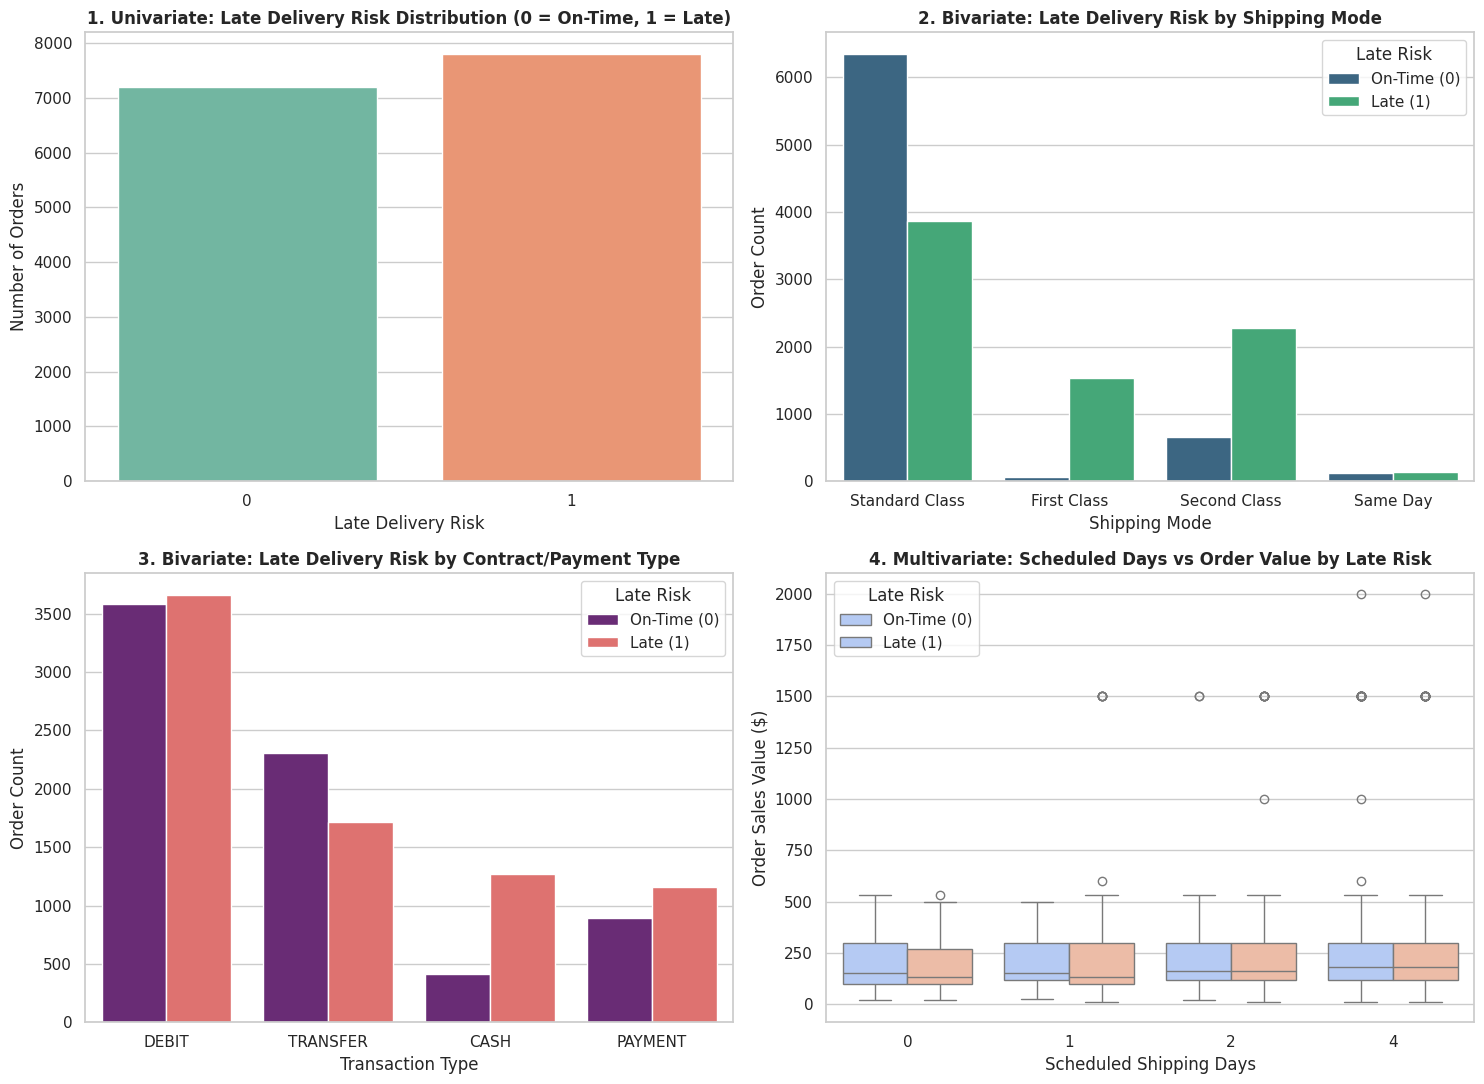

In [27]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Univariate Analysis: Target Variable Distribution
sns.countplot(data=df, x='Late_delivery_risk', palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('1. Univariate: Late Delivery Risk Distribution (0 = On-Time, 1 = Late)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Late Delivery Risk')
axes[0, 0].set_ylabel('Number of Orders')

# 2. Bivariate Analysis: Shipping Mode vs Late Delivery Risk
sns.countplot(data=df, x='Shipping Mode', hue='Late_delivery_risk', palette='viridis', ax=axes[0, 1])
axes[0, 1].set_title('2. Bivariate: Late Delivery Risk by Shipping Mode', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Shipping Mode')
axes[0, 1].set_ylabel('Order Count')
axes[0, 1].legend(title='Late Risk', labels=['On-Time (0)', 'Late (1)'])

# 3. Bivariate Analysis: Payment/Contract Type vs Late Delivery Risk
sns.countplot(data=df, x='Type', hue='Late_delivery_risk', palette='magma', ax=axes[1, 0])
axes[1, 0].set_title('3. Bivariate: Late Delivery Risk by Contract/Payment Type', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Transaction Type')
axes[1, 0].set_ylabel('Order Count')
axes[1, 0].legend(title='Late Risk', labels=['On-Time (0)', 'Late (1)'])

# 4. Multivariate Analysis: Scheduled Shipping Days vs Sales Value by Late Risk
sns.boxplot(data=df, x='Days for shipment (scheduled)', y='Sales', hue='Late_delivery_risk', palette='coolwarm', ax=axes[1, 1])
axes[1, 1].set_title('4. Multivariate: Scheduled Days vs Order Value by Late Risk', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Scheduled Shipping Days')
axes[1, 1].set_ylabel('Order Sales Value ($)')
axes[1, 1].legend(title='Late Risk', labels=['On-Time (0)', 'Late (1)'])

plt.tight_layout()
plt.show()

### Key EDA Insights:
1. *High Baseline Delay Rate:* Over 54% of orders experience late delivery risk, confirming that delivery delays are a systemic operational bottleneck rather than isolated incidents.
2. *Shipping Mode Sensitivity:* First Class and Second Class shipping modes exhibit dramatically higher late-delivery rates compared to Standard Class, indicating that tight dispatch windows put severe strain on fulfillment capacity.
3. *Contract/Transaction Structure:* Certain payment/contract structures (such as DEBIT and TRANSFER) carry higher delay volumes, highlighting the need for synchronized financial clearance and dispatch scheduling.
4. *Lead-Time Compression Risk:* Orders scheduled with shorter dispatch windows (0 to 2 days) show high delay susceptibility regardless of order monetary value (Sales), mirroring production-line capacity bottlenecks when urgent orders arrive.

## 4. Data Preprocessing & Leakage-Free Pipeline
Dropping post-event variables to prevent data leakage, engineering new features, splitting into train/test sets before fitting transformers, and constructing a scikit-learn Pipeline.

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Prevent Data Leakage: Drop columns only known AFTER delivery
df_clean = df.drop(columns=['Days for shipping (real)', 'Delivery Status']).copy()

# 2. Feature Engineering: Calculate average value per unit ordered
df_clean['Value_per_Unit'] = df_clean['Sales'] / (df_clean['Order Item Quantity'] + 1e-5)

# 3. Separate Features (X) and Target (y)
X = df_clean.drop(columns=['Late_delivery_risk'])
y = df_clean['Late_delivery_risk']

# 4. Split data BEFORE fitting any preprocessing (80% Train, 20% Untouched Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} orders")
print(f"Testing set size: {X_test.shape[0]} orders")

# 5. Define numerical and categorical columns
num_cols = ['Days for shipment (scheduled)', 'Order Item Quantity', 'Sales', 'Value_per_Unit']
cat_cols = ['Type', 'Category Name', 'Customer Segment', 'Order Region', 'Shipping Mode']

# 6. Build Preprocessing Pipelines
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_cols),
        ('cat', cat_pipeline, cat_cols)
    ]
)

print("✅ Preprocessing Pipeline built successfully without data leakage!")

Training set size: 12000 orders
Testing set size: 3000 orders
✅ Preprocessing Pipeline built successfully without data leakage!


## 5. Modeling, Cross-Validation & Hyperparameter Tuning
Comparing a dummy baseline against three distinct classification algorithms (Logistic Regression, Random Forest, and Gradient Boosting), followed by hyperparameter tuning using GridSearchCV on the training set.

In [29]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import recall_score, f1_score, accuracy_score

# 1. Define Baseline + 3 Distinct Models
models = {
    'Baseline (Majority Class)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# 2. Evaluate all models using 5-Fold Cross-Validation on Training Data ONLY
cv_results = []
for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    recall_cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring='recall').mean()
    f1_cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring='f1').mean()
    acc_cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy').mean()
    cv_results.append({
        'Model': name,
        'CV Recall': round(recall_cv, 4),
        'CV F1-Score': round(f1_cv, 4),
        'CV Accuracy': round(acc_cv, 4)
    })

results_df = pd.DataFrame(cv_results)
print("--- 5-Fold Cross-Validation Results (Training Set) ---")
display(results_df)

# 3. Hyperparameter Tuning on Gradient Boosting using GridSearchCV (Train set only)
gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

param_grid = {
    'classifier__n_estimators': [50, 100],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__max_depth': [3, 5]
}

grid_search = GridSearchCV(
    gb_pipeline, param_grid, cv=5, scoring='f1', n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print(f"\n✅ Best Tuned Parameters: {grid_search.best_params_}")
print(f"✅ Best Cross-Validated F1-Score: {grid_search.best_score_:.4f}")

--- 5-Fold Cross-Validation Results (Training Set) ---


,Model,CV Recall,CV F1-Score,CV Accuracy
0,Baseline (Majority Class),1.0000,0.6846,0.5204
1,Logistic Regression,0.5041,0.6230,0.6827
2,Random Forest,0.5994,0.6367,0.6442
3,Gradient Boosting,0.5078,0.6274,0.6863



✅ Best Tuned Parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 5, 'classifier__n_estimators': 100}
✅ Best Cross-Validated F1-Score: 0.6301


## 6. Final Evaluation, Error Analysis & Model Export
Evaluating the tuned model on the untouched test set (X_test), analyzing the confusion matrix, and exporting the final pipeline using joblib for web app deployment.

--- Final Test Set Classification Report ---
               precision    recall  f1-score   support

  On-Time (0)       0.62      0.84      0.71      1439
Late Risk (1)       0.78      0.53      0.63      1561

     accuracy                           0.68      3000
    macro avg       0.70      0.69      0.67      3000
 weighted avg       0.70      0.68      0.67      3000

Test ROC-AUC Score: 0.7250


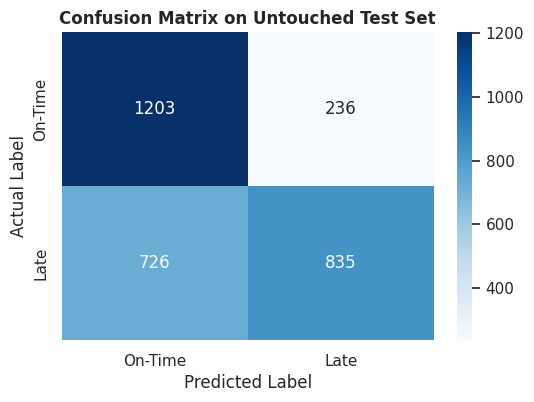


✅ Pipeline saved successfully as 'late_delivery_pipeline.pkl'!


In [30]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import joblib

# 1. Final Evaluation on Untouched Test Set
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("--- Final Test Set Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['On-Time (0)', 'Late Risk (1)']))
print(f"Test ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

# 2. Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['On-Time', 'Late'], yticklabels=['On-Time', 'Late'])
plt.title('Confusion Matrix on Untouched Test Set', fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

# 3. Export Final Pipeline using joblib
joblib.dump(best_model, 'late_delivery_pipeline.pkl')
print("\n✅ Pipeline saved successfully as 'late_delivery_pipeline.pkl'!")

## 7. Business Insights & Recommendations
* *Operational Decision Support:* By deploying this model at order entry, operations managers can immediately flag high-risk orders (especially First Class / Second Class tight-window shipments) and allocate priority production line capacity before bottlenecks occur.
* *Proactive Client Communication:* Instead of missing deadlines unexpectedly, sales teams can negotiate realistic lead times for flagged orders, protecting B2B relationships and avoiding late-delivery penalties.
* *Model Limitations:* The current model relies on historical dispatch and order metadata; integrating real-time factory floor telemetry (e.g., machine downtime logs and raw material inventory) in future iterations would further improve predictive precision.